# 03 · La structure du marché : compétences, réseaux et familles de métiers

L'étape 4 a découpé les textes « compétences attendues » en items. Cette étape s'en sert pour décrire le marché :
1. Quelles compétences sont demandées partout, et lesquelles signent un métier ?
2. Quelles compétences vont ensemble (réseau de cooccurrence) ?
3. Quelles familles de métiers se dessinent quand on les compare par leurs compétences ?
4. Zoom : que demande-t-on aux métiers de la data ?

**Périmètre** : les annonces qui ont un texte de compétences (4,5 % des offres, surtout à l'État et à l'hôpital), pour
les métiers qui en ont au moins 20. On travaille sur les **formes** des items (texte normalisé, « rigueur »,
« techniques du bâtiment ») plutôt que sur leur rattachement au ROME : à l'échelle d'un item, ce rattachement n'est exact
qu'une fois sur trois (notebook 02), alors que les formes fréquentes sont propres.

In [1]:
import os
import warnings

os.environ["TQDM_DISABLE"] = "1"  # pas de barres de progression au chargement du modèle d'embeddings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import networkx as nx
import numpy as np
import polars as pl
from sklearn.decomposition import NMF

from offres import competences as comp, donnees, familles as fam, graphiques as g, lexique, structure

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="IProgress not found")  # NMF à initialisation aléatoire (test de stabilité)
g.style()
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(80)
offres = donnees.offres_service_public()
items = pl.read_parquet(donnees.chemin("competences_items.parquet"))
x = structure.items_par_metier(items, offres)
print(f"{x['annonce_id'].n_unique():,} annonces, {x['metier'].n_unique()} métiers, {x['forme'].n_unique():,} formes distinctes")
print("Versant des annonces retenues :")
offres.filter(pl.col("annonce_id").is_in(x["annonce_id"].unique().implode())).unique("annonce_id").group_by("versant").len().with_columns(
    part=pl.col("len") / pl.col("len").sum()).sort("len", descending=True)

66,282 annonces, 414 métiers, 117,687 formes distinctes
Versant des annonces retenues :


versant,len,part
str,u32,f64
"""Fonction Publique de l'Etat""",57992,0.874928
"""Fonction Publique Hospitalière""",8089,0.122039
"""Fonction Publique Territoriale""",193,0.002912
null,8,0.000121


In [2]:
# Libellé lisible de chaque forme : la graphie la plus fréquente dans les offres
bruts = comp.items_des_offres(offres)
libelles = bruts.group_by("forme").agg(pl.col("item").mode().sort().first().alias("libelle"))
LIB = {f: (l.capitalize() if l.isupper() else l[0].upper() + l[1:]) for f, l in libelles.iter_rows()}
def lib(f, n=45):
    t = LIB.get(f, f)
    return t if len(t) <= n else t[: n - 1] + "…"

## 1. Un socle transversal, puis des compétences de métier

Pour chaque forme, on compte la part des métiers qui la citent au moins une fois. Au-delà d'un quart des métiers, elle
est dite **transversale** : elle ne dit rien du métier.

95 formes transversales sur 117,687 ; elles pèsent 29% des citations


PosixPath('/home/user/offres-emploi-competences/rapports/figures/14_competences_transversales.png')

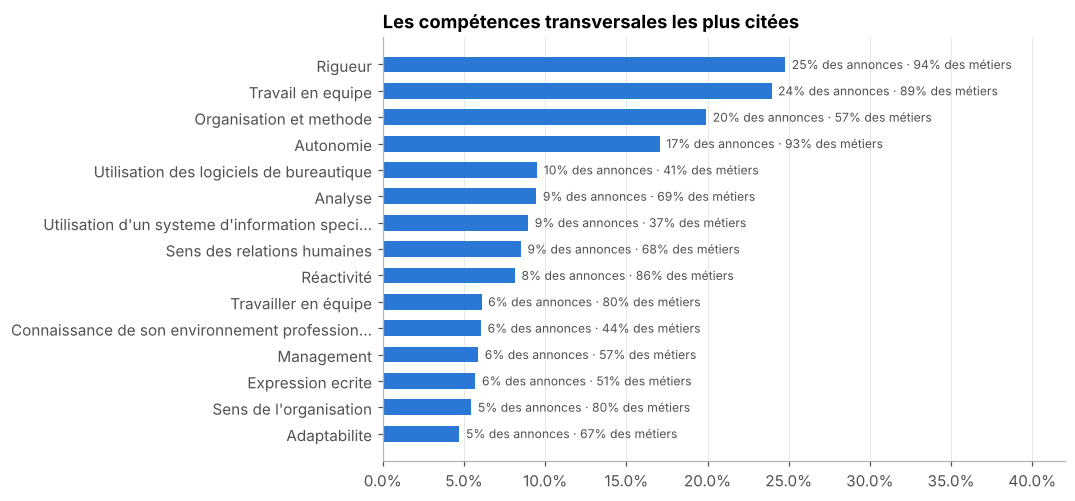

In [3]:
t = structure.transversalite(x)
print(f"{t['transversale'].sum()} formes transversales sur {t.height:,} ; "
      f"elles pèsent {t.filter('transversale')['annonces'].sum() / t['annonces'].sum():.0%} des citations")
top = t.filter("transversale").head(15).reverse()
n_ann = x["annonce_id"].n_unique()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([lib(f) for f in top["forme"]], top["annonces"] / n_ann, color=g.PALETTE[0], height=0.6)
for i, (a, pm) in enumerate(zip(top["annonces"] / n_ann, top["part_metiers"])):
    ax.text(a + 0.004, i, f"{a:.0%} des annonces · {pm:.0%} des métiers", va="center", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 0.42)
ax.grid(axis="y", visible=False)
ax.set_title("Les compétences transversales les plus citées")
g.enregistrer(fig, "14_competences_transversales")

Rigueur et travail en équipe reviennent dans une annonce sur quatre, autonomie dans une sur six, et presque tous les
métiers les citent. Ce socle vient sans doute en partie des référentiels de compétences des ministères, repris tels
quels dans les offres de l'État. Les analyses
qui suivent l'écartent pour faire ressortir ce qui distingue les métiers.

## 2. Quelles compétences vont ensemble ?

On relie deux compétences de métier quand elles sont citées dans les mêmes annonces plus souvent que le hasard ne le
voudrait. La mesure est l'information mutuelle ponctuelle normalisée (NPMI) : 0 pour deux compétences indépendantes,
1 pour deux compétences toujours citées ensemble. Les 150 compétences de métier les plus citées sont gardées, avec les
liens de NPMI au moins 0,3 vus dans 20 annonces ou plus, puis le graphe est découpé en communautés (méthode de Louvain).

In [4]:
specifiques = t.filter(~pl.col("transversale")).head(150)["forme"].to_list()
paires = structure.cooccurrences(x, specifiques, min_paires=20)
G, groupes = structure.communautes(paires, seuil_npmi=0.3)
freq = dict(zip(t["forme"], t["annonces"]))
print(f"{G.number_of_nodes()} compétences reliées, {G.number_of_edges()} liens, {len(groupes)} communautés : "
      f"{[len(c) for c in groupes]}")
for i, c in enumerate(groupes[:10]):
    print(f"{i + 1:2d}. " + " · ".join(lib(f, 38) for f in sorted(c, key=lambda f: -freq[f])[:6]))

148 compétences reliées, 646 liens, 9 communautés : [24, 22, 21, 18, 17, 15, 12, 11, 8]
 1. Respect des regles elementaires d'hyg… · Satisfaction de la demande d'un client · Connaissance des sic · Mise en oeuvre des mesures corrective… · Diagnostic suite a un incident · Conseil et expertise technique dans l…
 2. Circuits administratifs · Avoir le sens des relations humaines · Faire preuve de discrétion · Avoir le sens de l'organisation · Maîtriser les nouvelles technologies · Organisation judiciaire et administra…
 3. Mise en oeuvre la reglementation en s… · Regles du marche public de travaux · Techniques du batiment · Evaluation des risques professionnels · Estimation des couts d'une operation … · Regles de realisation d'une operation…
 4. Reglementation et jurisprudence de la… · Maitrise des risques des organismes -… · Connaissance des regles et procedures… · Connaissance des systemes d'informati… · Connaissance des principes et regles … · Utilisation d'un tableur
 5. Protection du s

PosixPath('/home/user/offres-emploi-competences/rapports/figures/15_reseau_competences.png')

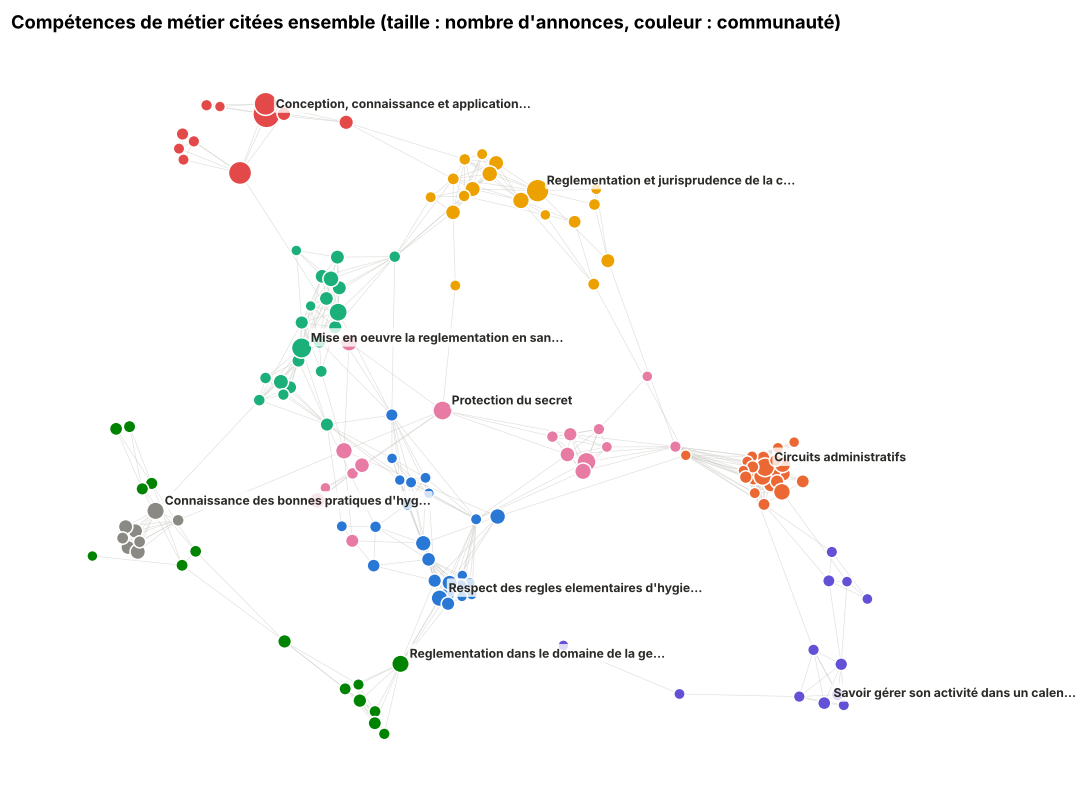

In [5]:
pos = nx.spring_layout(G, weight="weight", seed=3, k=0.35, iterations=200)
couleur = {}
for i, c in enumerate(groupes):
    for f in c:
        couleur[f] = g.PALETTE[i] if i < len(g.PALETTE) else g.GRIS
fig, ax = plt.subplots(figsize=(11, 9))
nx.draw_networkx_edges(G, pos, ax=ax, width=0.4, edge_color="#c9c8c2", alpha=0.6)
noeuds = list(G.nodes)
tailles = np.array([freq[f] for f in noeuds])
ax.scatter([pos[f][0] for f in noeuds], [pos[f][1] for f in noeuds], s=20 + 300 * tailles / tailles.max(),
           c=[couleur[f] for f in noeuds], edgecolors="white", linewidths=1, zorder=3)
# Une étiquette par communauté : sa compétence la plus citée (les huit plus grandes ont une couleur, les autres en gris)
for c in groupes:
    f = max(c, key=lambda f: freq[f])
    ax.annotate(lib(f, 40), pos[f], fontsize=8, fontweight="bold", color="#2b2a27", xytext=(6, 4),
                textcoords="offset points", zorder=4, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.set_axis_off()
ax.set_title("Compétences de métier citées ensemble (taille : nombre d'annonces, couleur : communauté)")
g.enregistrer(fig, "15_reseau_competences")

Une partie des communautés correspond à des domaines que l'on reconnaît sans les avoir nommés à l'avance : contrôle
interne et marchés publics, bâtiment et prévention des risques, systèmes d'information et de communication,
renseignement et protection du secret, restauration collective. Les autres montrent les
**gabarits** de rédaction : des compétences d'un même référentiel qui reviennent ensemble parce qu'elles sont copiées en
bloc d'une annonce à l'autre. C'est le cas du référentiel des Armées (« discipline », « connaissance du service
national »), de celui des universités (« travailler en réseau », « savoir gérer son activité dans un calendrier
contraint ») ou des savoir-être du secrétariat juridique (« circuits administratifs », « faire preuve de discrétion »).
Le réseau décrit donc autant la façon dont les employeurs écrivent leurs annonces que les métiers eux-mêmes.

## 3. Des familles de métiers

Chaque métier est décrit par la part de ses annonces qui citent chaque compétence de métier (pondérée par TF-IDF), puis
la matrice métiers × compétences est factorisée par NMF : chaque famille est une combinaison de compétences, et chaque
métier est rangé dans la famille où il pèse le plus. Le nombre de familles est choisi sur la **stabilité** : on refait
la factorisation avec des initialisations aléatoires et on mesure l'accord entre les découpages (indice de Rand ajusté).

Matrice : 414 métiers × 2,360 compétences de métier


k,ari_moyen,ari_min
i64,f64,f64
6,0.833527,0.70473
8,0.788846,0.640962
10,0.830405,0.715655
12,0.786237,0.562781
14,0.709303,0.485397
16,0.717961,0.51288
18,0.693277,0.529264
20,0.6518,0.538853


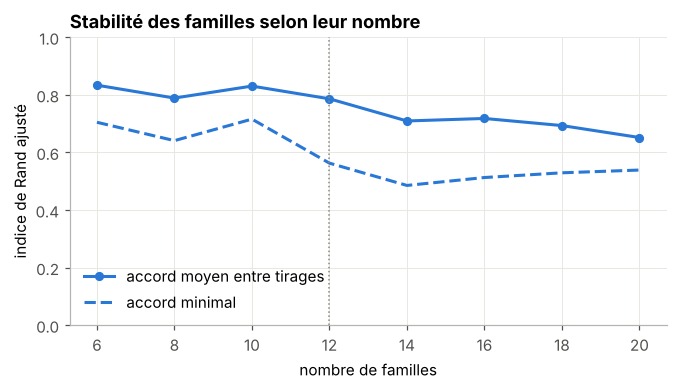

In [6]:
metiers, vocab, m = structure.matrice_metiers(x)
print(f"Matrice : {m.shape[0]} métiers × {m.shape[1]:,} compétences de métier")
stab = structure.stabilite(m, list(range(6, 21, 2)), graines=6)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(stab["k"], stab["ari_moyen"], "-o", color=g.PALETTE[0], ms=5, label="accord moyen entre tirages")
ax.plot(stab["k"], stab["ari_min"], "--", color=g.PALETTE[0], label="accord minimal")
ax.axvline(12, color=g.GRIS, lw=1, ls=":")
ax.set_ylim(0, 1)
ax.set_xlabel("nombre de familles")
ax.set_ylabel("indice de Rand ajusté")
ax.legend(loc="lower left")
ax.set_title("Stabilité des familles selon leur nombre")
g.enregistrer(fig, "16_stabilite_familles")
stab

L'accord reste autour de 0,8 jusqu'à douze familles, puis tombe vers 0,7 et en dessous. On garde donc **douze
familles**, le découpage le plus fin qui reste stable. On vérifie ensuite que **chaque famille** se retrouve d'un tirage
à l'autre : sa robustesse est le meilleur indice de Jaccard avec une famille d'un autre tirage, en moyenne sur six
tirages (1 = mêmes métiers).

In [7]:
K = 12
W, H = structure.familles(m, K)
etiquette = W.argmax(axis=1)
robustesse = np.zeros(K)
for graine in range(6):
    autre = NMF(K, init="random", random_state=graine, max_iter=1000).fit_transform(m).argmax(axis=1)
    for f in range(K):
        a = set(np.where(etiquette == f)[0])
        robustesse[f] += max(len(a & set(np.where(autre == u)[0])) / len(a | set(np.where(autre == u)[0])) for u in range(K)) / 6

# Nom de chaque famille, d'après ses compétences les plus caractéristiques (sous-chaîne recherchée dans ses 6 premières)
NOMS = [("cybersecurite", "Cybersécurité"), ("renseignement", "Renseignement"), ("culinaires", "Restauration collective"),
        ("achat", "Achats publics"), ("batiment", "Bâtiment, travaux, immobilier"), ("hospitaliere", "Soins et santé"),
        ("collections", "Archives, documentation, patrimoine"), ("judiciaire", "Juridique, greffe et cabinet"),
        ("sic", "Systèmes d'information et télécoms"), ("financ", "Finances, contrôle interne et pilotage"),
        ("ressources humaines", "Ressources humaines"), ("risques profes", "Environnement, prévention, sécurité au travail")]
# La plus grande famille est d'abord nommée à part : ses métiers ne citent guère que des compétences peu spécifiques
plus_grande = int(np.bincount(etiquette).argmax())
nom_famille = {plus_grande: "Profils peu spécifiques"}
for f in range(K):
    if f == plus_grande:
        continue
    tete = " | ".join(vocab[j] for j in np.argsort(-H[f])[:6])
    nom_famille[f] = next((n for cle, n in NOMS if cle in tete and n not in nom_famille.values()), None)
nom_famille = {f: n or f"Famille {f + 1}" for f, n in nom_famille.items()}

offres_metier = dict(offres.group_by("metier").len().drop_nulls("metier").iter_rows())
tableau = pl.DataFrame({
    "famille": [nom_famille[f] for f in range(K)],
    "metiers": np.bincount(etiquette, minlength=K),
    "offres": [sum(offres_metier.get(metiers[i], 0) for i in np.where(etiquette == f)[0]) for f in range(K)],
    "robustesse": robustesse.round(2),
    "competences_caracteristiques": [" · ".join(lib(vocab[j], 30) for j in np.argsort(-H[f])[:4]) for f in range(K)],
    "exemples": [" · ".join(metiers[i] for i in np.argsort(-W[:, f])[:3]) for f in range(K)],
}).sort("offres", descending=True)
tableau

famille,metiers,offres,robustesse,competences_caracteristiques,exemples
str,i64,i64,f64,str,str
"""Profils peu spécifiques""",161,359056,0.83,"""Utiliser les logiciels spécif… · Savoir gérer son activité dan… · Communiquer et…","""Chargée / Chargé de la coordination administrative · Chargée / Chargé du pilotag…"
"""Finances, contrôle interne et pilotage""",46,248885,0.71,"""Maitrise des risques des orga… · Conception, connaissance et a… · Demarche proce…","""Contrôleuse / Contrôleur de gestion · Responsable de l'activité de contrôle · Co…"
"""Soins et santé""",40,182164,0.78,"""Hygiene hospitaliere · Observation des regles de l'e… · Education therapeutique …","""Aide-soignante / Aide-soignant · Masseuse / Masseur kinésithérapeute · Infirmièr…"
"""Juridique, greffe et cabinet""",24,160301,0.79,"""Maîtrise de l'organisation ju… · Circuits administratifs · Qualité de rédaction …","""Assistante / Assistant juridique · Chargée / Chargé de l'appui juridique et méth…"
"""Environnement, prévention, sécurité au travail""",41,106893,0.82,"""Reglementation environnementa… · Evaluation des risques profes… · Mise en oeuvre…","""Responsable ou Chargée / Chargé de la maîtrise des risques · Chargée / Chargé de…"
"""Restauration collective""",14,56963,0.85,"""Connaissance des bonnes prati… · Connaissances des produits al… · Utilisation et…","""Chargée / Chargé de restauration, d'intendance · Chargée / Chargé de restauratio…"
"""Systèmes d'information et télécoms""",19,46244,0.74,"""Conseil et expertise techniqu… · Respect des regles elementair… · Connaissance d…","""Spécialiste outils, systèmes d'exploitation, réseaux et télécoms · Responsable r…"
"""Bâtiment, travaux, immobilier""",15,24269,0.89,"""Regles du marche public de tr… · Techniques du batiment · Regles de realisation …","""Cheffe / Chef de projet immobilier · Responsable de gestion de patrimoine immobi…"
"""Achats publics""",12,17612,0.95,"""Reglementation et jurispruden… · Negociation de l'achat · Politique d'achats · S…","""Acheteuse / Acheteur travaux, immobilier, énergies · Acheteuse spécialisée / Ach…"


Les 414 métiers classés représentent 76% des 1,6 million d'offres


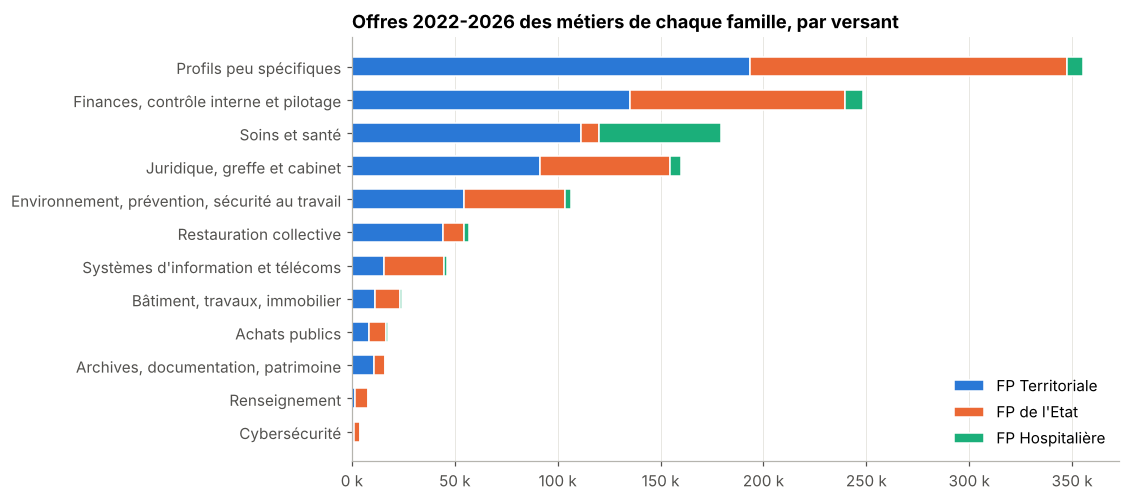

In [8]:
fam_metier = pl.DataFrame({"metier": metiers, "famille": [nom_famille[f] for f in etiquette]})
par_versant = (offres.join(fam_metier, on="metier").group_by("famille", "versant").len()
               .pivot(on="versant", index="famille", values="len").fill_null(0))
ordre = tableau.sort("offres")["famille"].to_list()
par_versant = par_versant.with_columns(pl.col("famille").cast(pl.Enum(ordre))).sort("famille")
fig, ax = plt.subplots(figsize=(9, 5))
gauche = np.zeros(par_versant.height)
for versant, couleur in g.VERSANTS.items():
    v = par_versant[versant].to_numpy() if versant in par_versant.columns else np.zeros(par_versant.height)
    ax.barh(par_versant["famille"].cast(pl.Utf8), v, left=gauche, color=couleur, height=0.6, label=versant.replace("Fonction Publique", "FP"),
            edgecolor="white", linewidth=1)
    gauche += v
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k"))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Offres 2022-2026 des métiers de chaque famille, par versant")
g.enregistrer(fig, "17_familles_metiers")
couverture = sum(offres_metier.get(mm, 0) for mm in metiers) / offres.height
print(f"Les {len(metiers)} métiers classés représentent {couverture:.0%} des 1,6 million d'offres")

Onze familles correspondent à des domaines nets : finances et contrôle interne, soins, juridique, prévention et
environnement, restauration collective, systèmes d'information, bâtiment, achats publics, archives et patrimoine,
renseignement, cybersécurité. Toutes se retrouvent d'un tirage à l'autre (robustesse de 0,71 à 0,95). La douzième, la
plus grande (161 métiers), réunit des métiers dont les textes ne citent guère que des compétences génériques
(« utiliser les logiciels spécifiques à l'activité », « communiquer ») : c'est une limite des textes plus qu'une famille
de métiers.

### Peut-on classer tous les métiers par leur seul intitulé ?

Les familles ne couvrent que les métiers qui ont des textes. Pour les autres, on pourrait ranger chaque métier dans la
famille de ses voisins les plus proches par l'intitulé (embeddings e5). Test en validation croisée sur les métiers déjà
classés :

In [9]:
from sklearn.model_selection import StratifiedKFold
from offres.embeddings import Modele

E = Modele("e5").encoder([comp.sans_double_genre(mm, True).lower() for mm in metiers])
def voisins(a, ya, b, k=5):
    s = b @ a.T
    proches = np.argsort(-s, axis=1)[:, :k]
    return np.array([np.bincount(ya[p], weights=s[i, p], minlength=K).argmax() for i, p in enumerate(proches)])
prevu = np.zeros(len(metiers), int)
for app, test in StratifiedKFold(5, shuffle=True, random_state=0).split(E, etiquette):
    prevu[test] = voisins(E[app], etiquette[app], E[test])
print(f"Bonne famille retrouvée par l'intitulé : {(prevu == etiquette).mean():.0%} "
      f"(toujours répondre la plus grande famille : {np.bincount(etiquette).max() / len(etiquette):.0%})")

Bonne famille retrouvée par l'intitulé : 56% (toujours répondre la plus grande famille : 39%)


Un peu plus d'une fois sur deux seulement, à peine mieux que la règle naïve : l'intitulé ne suffit pas. Les familles
restent donc décrites sur les métiers qui ont des textes, et l'on ne prête pas de famille aux autres.

## 4. Zoom : les métiers de la data

Le notebook 01 a montré une niche (0,7 % des offres), de cadres, très ouverte au télétravail. Que leur demande-t-on ?

11,367 offres data, dont 776 avec un texte de compétences
Famille des métiers data classés : [('Profils peu spécifiques', 9), ('Archives, documentation, patrimoine', 1), ('Finances, contrôle interne et pilotage', 1), ("Systèmes d'information et télécoms", 1)]


forme,d,part_data,part_tous,lift
str,u32,f64,f64,f64
"""proposition de solutions optimisees par le biais de methodes scientifiques""",35,0.045103,0.00084,53.662571
"""statistiques exploitation de donnees""",76,0.097938,0.00213,45.975629
"""science des donnees""",33,0.042526,0.001101,38.612843
"""architectures et techniques big data""",56,0.072165,0.001971,36.616813
"""informatique decisionnelle""",39,0.050258,0.001724,29.143994
"""conception d un modele de donnees conformement aux standards""",47,0.060567,0.002232,27.13992
"""identification des donnees du systeme d information conformement aux standards""",41,0.052835,0.002348,22.506101
"""developpement d un systeme informatique""",29,0.037371,0.004101,9.112614
"""creativite""",37,0.04768,0.009695,4.91821


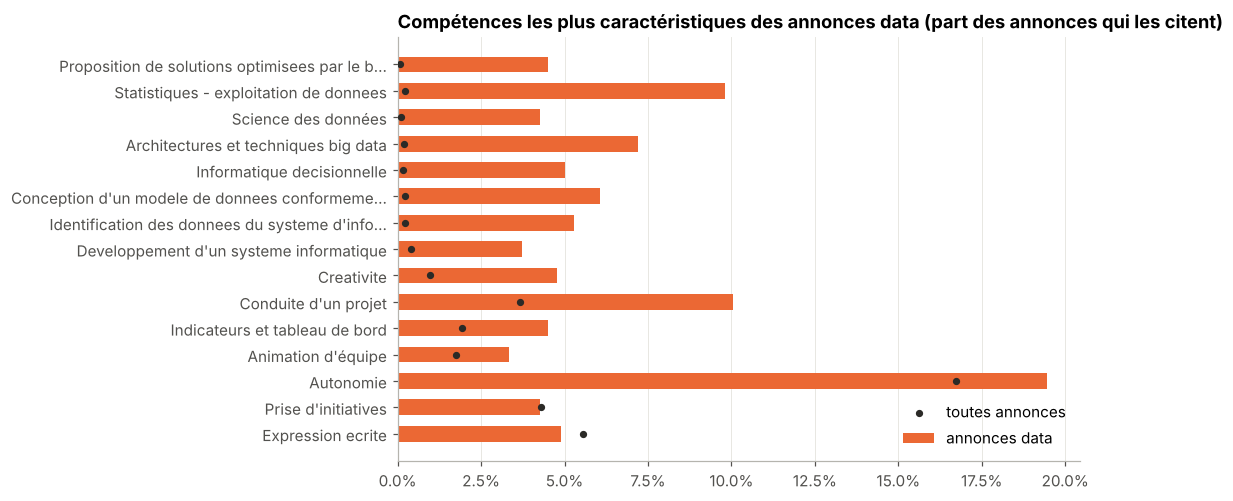

In [10]:
data = offres.filter(fam.est_data())
ann_data = set(data["annonce_id"].to_list())
xd = items.unique(["annonce_id", "forme"]).with_columns(data=pl.col("annonce_id").is_in(list(ann_data)))
n_d = xd.filter("data")["annonce_id"].n_unique()
n_tot = xd["annonce_id"].n_unique()
print(f"{data.height:,} offres data, dont {n_d} avec un texte de compétences")
print("Famille des métiers data classés :", fam_metier.filter(fam.est_data()).group_by("famille").len().sort(["len", "famille"], descending=[True, False]).rows())
part = (xd.group_by("forme").agg(d=pl.col("annonce_id").filter(pl.col("data")).n_unique(), n=pl.col("annonce_id").n_unique())
        .with_columns(part_data=pl.col("d") / n_d, part_tous=pl.col("n") / n_tot)
        .with_columns(lift=pl.col("part_data") / pl.col("part_tous"))
        .filter(pl.col("d") >= 25).sort("lift", descending=True))
top_d = part.head(15).reverse()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([lib(f) for f in top_d["forme"]], top_d["part_data"], color=g.PALETTE[1], height=0.6, label="annonces data")
ax.scatter(top_d["part_tous"], range(top_d.height), color="#2b2a27", s=14, zorder=3, label="toutes annonces")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Compétences les plus caractéristiques des annonces data (part des annonces qui les citent)")
g.enregistrer(fig, "18_competences_data")
part.head(15).select("forme", "d", "part_data", "part_tous", "lift")

In [11]:
outils = (data.unique("annonce_id")
          .with_columns(outils=pl.concat_str([pl.col("intitule").fill_null(""), pl.col("competences_texte").fill_null(""),
                                              pl.col("specialisation").fill_null("")], separator=" ")
                        .map_elements(lexique.extraire, return_dtype=pl.List(pl.Utf8))))
avec = outils.filter(pl.col("outils").list.len() > 0)
print(f"Outils repérés dans {avec.height} annonces data sur {outils.height:,} ({avec.height / outils.height:.0%})")
avec.explode("outils").group_by("outils").len().with_columns(part=pl.col("len") / avec.height).sort("len", descending=True).head(15)

Outils repérés dans 1183 annonces data sur 11,239 (11%)


outils,len,part
str,u32,f64
"""Statistiques""",455,0.384615
"""Intelligence artificielle""",131,0.110735
"""Python""",123,0.103973
"""SIG (QGIS, ArcGIS)""",119,0.100592
"""Anglais""",110,0.092984
"""Big data""",74,0.062553
"""Machine learning""",73,0.061708
"""Cybersécurité""",70,0.059172
"""Excel""",67,0.056636


Les annonces data se distinguent par la statistique et l'exploitation de données, la science des données, le big
data, l'informatique décisionnelle et la modélisation de données, puis, plus loin, la conduite de projet et les
tableaux de bord. Leurs métiers, eux, tombent pour la plupart (9 sur 12) dans la famille peu spécifique : peu de leurs
annonces ont un texte de compétences (776), et la data se répartit entre des métiers d'études et de pilotage plutôt
qu'elle ne forme un domaine à part dans les offres publiques.

Les outils sont rarement nommés : on en trouve dans une annonce data sur dix seulement, parce que le fichier ouvert ne
contient pas la description complète du poste. Parmi elles, la statistique domine (38 %), loin devant l'intelligence
artificielle, Python et les SIG (10 à 11 % chacun) ; SQL n'apparaît que dans 4 % d'entre elles. Le reste du marché
(France Travail, si l'accès arrive) dira si le privé demande les mêmes.

## À retenir

- Un **socle transversal** (rigueur, travail en équipe, autonomie, organisation) revient dans presque tous les métiers ;
  il pèse lourd dans les citations mais ne distingue personne.
- Les **compétences de métier** forment des communautés lisibles (contrôle et marchés, bâtiment, systèmes
  d'information, renseignement, restauration), où se lisent aussi les gabarits de rédaction des Armées, des
  universités ou des juridictions.
- Une NMF sur les profils de compétences donne **douze familles** de métiers stables d'un tirage à l'autre ; onze sont
  des domaines nets, la douzième regroupe les métiers dont les textes restent trop génériques.
- L'**intitulé seul** ne suffit pas à ranger un métier dans sa famille (une fois sur deux) : on ne généralise pas aux
  métiers sans texte.
- Les métiers de la **data** se reconnaissent à la statistique, à la science des données et au décisionnel ; les
  outils précis ne sont écrits que dans une annonce sur dix, trop peu pour classer les technologies.